# Neural Network (MLP)

This notebook investigates an MLP neural network to predict players total FPL points. Different settings are tested including network capacity, random seeds and regularisation to see how they affect model performance. The results are evaluated using 5-fold cross validation and then compared with the best model from notebook 3, 03_model_comparison.

## Setup

In [57]:
import sys
sys.path.append("../src")
from read_data import load_data
from preprocess import prepare_data, build_preprocessor
from evaluation import cv_model
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
import pandas as pd

In [58]:
df = load_data()
X, y = prepare_data(df)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape)
print("Test rows:", X_test.shape)

Training rows: (429, 7)
Test rows: (108, 7)


## MLP model

I will create a small MLP containing one layer of 32 neurons because the dataset is small.

The model will use the following settings:

- **Activation:** ReLU, non linear activation funcction
- **Optimiser:** Adam, which updates the network weights during training.
- **Loss function:** Squared error, measures prediction errors during training.
- **Batch size:** Auto, uses batches of up to 200 training samples.
- **Stopping rule:** Early stopping, stops training when validation performance stops improving.
- **Maximum iterations:** 500, the number of training iterations.

In [59]:
# MLP1: One hidden layer with 32 neurons
mlp1 = make_pipeline(
    build_preprocessor(),
    MLPRegressor(
        hidden_layer_sizes=(32,),
        activation="relu", solver="adam",
        alpha=1e-4, early_stopping=True,
        max_iter=500, random_state=42
    )
)

mlp1.fit(X_train, y_train)
fitted1 = mlp1.named_steps["mlpregressor"]
print(f"MLP1 Iterations: {fitted1.n_iter_}")
print(f"MLP1 Loss: {fitted1.loss_:.2f}")

MLP1 Iterations: 500
MLP1 Loss: 87.07


c:\College\Year4\Ml\CT4101_ML_FPL_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP1 reached the maximum 500 iterations without fully converging. This means it may need more training to fully improve.

### MLP model with two hidden layers (64 and 32 Neurons)

I will now increase the network capacity by using two hidden layers containing 64 and 32 neurons, to see whether a larger network can improve prediction accuracy compared with MLP1.

All other model settings will remain the same.

In [60]:
# MLP2: Two hidden layers with 64 and 32 neurons
mlp2 = make_pipeline(
    build_preprocessor(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu", solver="adam",
        alpha=1e-4, early_stopping=True,
        max_iter=500,random_state=42
    )
)
# Train with larger model and examine the training results
mlp2.fit(X_train, y_train)
fitted2 = mlp2.named_steps["mlpregressor"]
print(f"MLP2 Iterations: {fitted2.n_iter_}")
print(f"MLP2 Loss: {fitted2.loss_:.2f}")

MLP2 Iterations: 156
MLP2 Loss: 80.22


MLP2 stopped after approximately 156 iterations because its predictions were no longer improving.

## Plot training loss

The graph shows how training loss changes during training for both networks. Lower training loss means the model is fitting the training data better. It also shows how quickly each network learns.

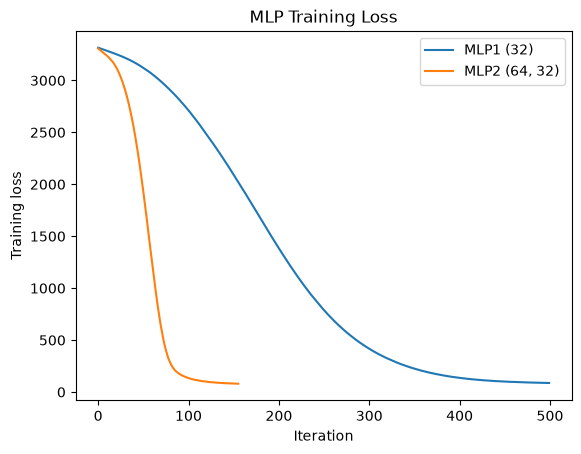

In [61]:
plt.plot(fitted1.loss_curve_, label="MLP1 (32)")
plt.plot(fitted2.loss_curve_, label="MLP2 (64, 32)")
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.title("MLP Training Loss")
plt.legend()
plt.show()

The training loss decreases for both models, showing that they are learning. MLP2 improves faster than MLP1.

## Plot Internal Validation R²

The graph shows the validation R² recorded during training. A higher R² means the model makes better predictions. The graph shows whether the models are improving during training.

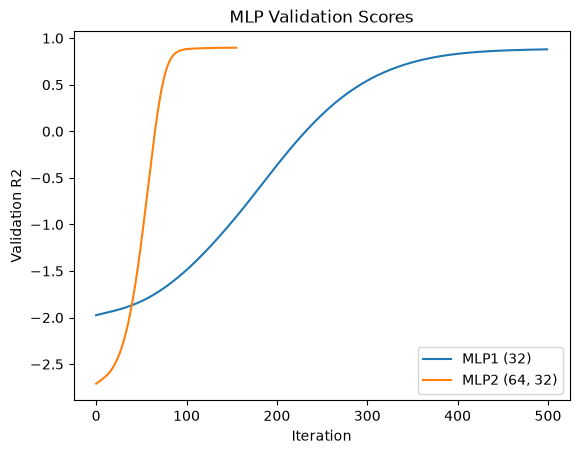

In [62]:
plt.plot(fitted1.validation_scores_, label="MLP1 (32)")
plt.plot(fitted2.validation_scores_, label="MLP2 (64, 32)")
plt.xlabel("Iteration")
plt.ylabel("Validation R2")
plt.title("MLP Validation Scores")
plt.legend()
plt.show()

Both models improve during training. MLP2 reached a higher R² in fewer iterations. So MLP2 learns faster and makes slightly better predictions.

## Cross Validation comparison 
Compare both networks using the same 5-fold cross validation
MAE is the main metric, with RMSE and R2 as secondary metrics.  Fit time and train time are also compared.

In [63]:
mlp1_cv = cv_model(mlp1, X_train, y_train)
mlp2_cv = cv_model(mlp2, X_train, y_train)

c:\College\Year4\Ml\CT4101_ML_FPL_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\College\Year4\Ml\CT4101_ML_FPL_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [64]:
print("      MLP Cross Validation Results")

mlp_results = pd.DataFrame({
    "MLP1 (32)": pd.DataFrame(mlp1_cv).mean(),
    "MLP2 (64,32)": pd.DataFrame(mlp2_cv).mean()
})


display(mlp_results.round(2))

      MLP Cross Validation Results


,MLP1 (32),"MLP2 (64,32)"
MAE,10.88,10.53
RMSE,14.50,14.01
R2,0.91,0.92
fit_time,0.70,0.32
score_time,0.01,0.01


MLP2 performs a little better than MLP1. It has a lower MAE and RMSE and a higher R². However, the difference between the two models is small. MLP2 also trains faster. Both models have similar scoring times.

## Test with different seeds 
Three random seeds are tested to see how much the performance of MLP2 changes.

In [65]:
seed_results=pd.DataFrame()
for seed in [21, 42, 99]:

    mlp_seed = make_pipeline(
        build_preprocessor(),
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",solver="adam",
            alpha=1e-4, early_stopping=True,
            max_iter=500, random_state=seed
        )
    )

    results = cv_model(mlp_seed, X_train, y_train)
    seed_results[seed] = pd.DataFrame(results)[["MAE", "RMSE", "R2"]].mean()
display(seed_results.round(2))

,21,42,99
MAE,12.11,10.53,11.05
RMSE,15.89,14.01,14.43
R2,0.90,0.92,0.91


MLP2 was tested with three different seeds (21, 42 and 99). Seed 42 gave the best results. The results were slightly different for each seed.

## Regularisation
L2 weight decay helps keep the neural networks weights small to reduce overfitting. The alpha parameter is used to control how much the weights are kept small.
MLP2 is tested with a stronger aplha value of 0.01 to see whether prediction accuracy improves over the default 0.0001

In [66]:
mlp_reg = make_pipeline(
    build_preprocessor(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu", solver="adam",
        alpha=0.01, early_stopping=True,
        max_iter=500, random_state=42
    )
)

reg_cv = cv_model(mlp_reg, X_train, y_train)

comparison = pd.DataFrame({
    "Original (0.0001)": pd.DataFrame(mlp2_cv).mean(),
    "Regularised (0.01)": pd.DataFrame(reg_cv).mean()
})

display(comparison.round(2))

,Original (0.0001),Regularised (0.01)
MAE,10.53,10.54
RMSE,14.01,14.02
R2,0.92,0.92
fit_time,0.32,0.43
score_time,0.01,0.01


Increasing alpha from 0.0001 to 0.01 made very little difference. MAE increased slightly from 10.53 to 10.54, and R² remained at 0.92.

## Comparison with Classical Machine Learning Model

In Notebook 03 Linear Regression was selected as the preferred classical machine learning model.

I will now compare Linear Regression with the best neural network (MLP 2) using five-fold cross-validation. I will compare their MAE, RMSE, R² and training times to determine whether the neural network offers any improvement.

In [67]:
linreg = make_pipeline(build_preprocessor(), LinearRegression())
lr_cv = cv_model(linreg, X_train, y_train)

In [68]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "MLP 2 (64, 32)"],
    "MAE": [lr_cv["MAE"].mean(), mlp2_cv["MAE"].mean()],
    "RMSE": [lr_cv["RMSE"].mean(), mlp2_cv["RMSE"].mean()],
    "R2": [lr_cv["R2"].mean(), mlp2_cv["R2"].mean()],
    "Training time (secs)": [lr_cv["fit_time"].mean(), mlp2_cv["fit_time"].mean()]
})

display(comparison.round(2))

,Model,MAE,RMSE,R2,Training time (secs)
0,Linear Regression,9.85,12.89,0.93,0.01
1,"MLP 2 (64, 32)",10.53,14.01,0.92,0.32


## **Conclusion**

**The model comparison was carried out using cross validation on the training dataset only.**

Linear Regression performed better than MLP2 on all evaluated metrics. It has a lower MAE, a lower RMSE and a slightly higher R².

Linear Regression was also much faster to train.

**These results show that the more complex neural network did not improve prediction accuracy. Therefore, Linear Regression is selected for final evaluation using the test dataset.**